# Homework 1 — Regression

This homework is focused on a complete regression workflow: data preparation, model training, hyperparameter tuning, model selection, and final evaluation.

The homework is worth **15 points**.

- Deadlines and submission rules are listed at [https://courses.fit.cvut.cz/BIE-ML1/homeworks/index.html](https://courses.fit.cvut.cz/BIE-ML1/homeworks/index.html).
- Submit the completed notebook together with the output file `results.csv`.
- Use Markdown cells to briefly explain important decisions and results. Keep the notebook clear and reasonably concise.
- If you submit the homework after the first deadline but before the final deadline, you will receive a penalty of **-7 points**. Submissions after the final deadline will receive no points.

> **The homework is intentionally open-ended in several places. Choosing an appropriate way to solve the individual parts of the task is part of the assignment. Your decisions should be reasonable and briefly justified.**

> **A complete solution should demonstrate sufficient experimentation and understanding of the methods.**

## Data

Your task is to predict the selling price of used cars.

You are given:

- `data.csv` — data containing the target variable `Price`,
- `evaluation.csv` — previously unseen data without `Price`, used for final evaluation.

### Variables

- `ID` — record identifier
- `Make` — car manufacturer
- `Price` — selling price; **target variable**
- `Year` — year of manufacture
- `Kilometer` — mileage in kilometres
- `Fuel Type` — fuel type
- `Transmission` — transmission type
- `Location` — city where the car was sold
- `Color` — car colour
- `Owner` — ownership information
- `Seller Type` — type of seller
- `Engine` — engine displacement
- `Drivetrain` — driven wheels
- `Length` — vehicle length in mm
- `Width` — vehicle width in mm
- `Height` — vehicle height in mm
- `Seating Capacity` — number of seats
- `Fuel Tank Capacity` — fuel tank capacity in litres

Some variables are numerical, some are categorical, some require a simple transformation, and some values are missing.

## Tasks
* Load the data from `data.csv` into the notebook. Split the dataset appropriately into subsets that will be used for model training (training set), model comparison (validation set), and subsequent estimation of the performance of the final model (test set).

* Perform basic data preprocessing:
  * Inspect the individual features and transform them into a suitable form for use with the selected regression models. For example, extract the numerical value from the `Engine` feature.
  * Handle missing values using some simple approach (e.g. replace them with a selected constant or another simple value). *Be careful about methodological errors!*
  * You may also use visualizations where appropriate. Briefly but sufficiently comment on your choices and results.

* Apply **linear regression**, **ridge regression**, and one of the following regression models: **decision tree** or **k-nearest neighbours**. For each model, as appropriate:
  * Comment on the suitability of the model for this type of problem.
  * Experiment with feature scaling (standardization / min-max scaling) if you expect it to have a beneficial effect on the model.
  * Select the main hyperparameter(s) to tune, where applicable, and find suitable values with respect to MSE.
  * For the model with the best hyperparameter values on the validation set, report its MSE.
  * Briefly comment on the obtained results.

* From all the considered models, select the final model and correctly estimate the prediction error, measured by RMSE (i.e. the square root of MSE), that you can expect on new data that have not been available to you so far. *Be careful about methodological errors!*

* Finally, load the evaluation data from `evaluation.csv` and use your final model to compute predictions for these data. Create a file `results.csv` containing the predictions in a column named **Price** and the corresponding identifiers in a column named **ID** (keep these column names exactly). Submit this file together with the notebook.

  An example of the first few rows of `results.csv` (with generally different values of `Price`) is:

```text
ID,Price
548,450000
879,680000
...
```


Store `results.csv` next to this notebook and submit both files.

## What should be explained in the notebook?

You do not need to write long descriptions. Briefly explain:

1. which variables you removed, if any, and why,
2. how you handled categorical and missing values,
3. when and why you used scaling,
4. which hyperparameter values you tried and which were selected,
5. why you selected the final model,
6. what test RMSE you obtained and what it means.


# The imports

In [17]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, TargetEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler
from sklearn.linear_model import LinearRegression, Ridge
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error, root_mean_squared_error
from sklearn.model_selection import ParameterGrid
from sklearn.preprocessing import FunctionTransformer
from sklearn.tree import DecisionTreeRegressor

# Helper functions

In [18]:
def output(y, y_pred):
    print(f"RMSE: {root_mean_squared_error(y_true=y, y_pred=y_pred)}")
    print(f"MSE: {mean_squared_error(y_true=y, y_pred=y_pred)}")
    print(f"R2 score: {r2_score(y, y_pred)}")

    plt.scatter(y, y_pred)
    plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r')
    plt.show()

def raw_data_preprocessing(df, drop_color=True, add_volume=True):
    df = df.drop(["ID"], axis=1)
    if drop_color:
        df = df.drop('Color', axis=1)
    if add_volume:
        df['Volume'] = df['Length'] * df['Width'] * df['Height']

    # Convert Engine to integer
    df["Engine"] = df["Engine"].str.extract(r"(\d+)", expand=False).astype(float)
    return df

# 1-2. Data preparation and processing
## Data preparation
1. Data was loaded into Pandas DataFrame and using the `na_values` parameter I tried to unify the representation of missing value into a standart one.
2. The `ID` feature was dropped as it doesn't carry any useful information for the model and could cause overfitting in some cases. `Color` was dropped as well and the `Volume` feature (`Length` * `Width` * `Height`) was added, I check both of these choices in the ablation at the end of the Data Processing section.
3. The `Engine` feature was transformed into a float by using RegEx. Float was used because it can carry the NaN, meanwhile int cannot.
4. The data was split into the Xtrain, Xval, and Xtest sets using the 60/20/20 division.

In [19]:
# 1. Data preparation
# 1.1 Load the data from `data.csv` into the notebook.
na_values = ["", "?", "N/A", "n/a", "NA", "null", "None", "-", "--", "nan"]
df = pd.read_csv('data.csv', na_values=na_values)
df = raw_data_preprocessing(df)

# 1.2 Split the dataset into training set, validation set, test set.
seed = 123

Xdata = df.drop(columns='Price')
ydata = df.Price

Xtrain, Xtemp, ytrain, ytemp = train_test_split(
    Xdata, ydata,
    test_size = 0.4,
    random_state=seed
)

Xval, Xtest, yval, ytest = train_test_split(
    Xtemp, ytemp,
    test_size = 0.5,
    random_state=seed
)

print("train:", Xtrain.shape, ytrain.shape)
print("validation:", Xval.shape, yval.shape)
print("test:", Xtest.shape, ytest.shape)

train: (1009, 16) (1009,)
validation: (337, 16) (337,)
test: (337, 16) (337,)


## Data exploration
Before the processing I explored only the training set, so nothing from the validation and test sets could affect my decisions.
1. Only `Engine` (9), `Drivetrain` (40) and `Fuel Tank Capacity` (27) have missing values, out of 1009 training rows. Removing those rows would throw away a lot of data, so I impute them.
2. `Price` is right-skewed. After applying `log()` the data is more bell-shaped. That's why the models are trained on `log(Price)` and `exp()` is applied to their predictions.
3. `Year` and `Kilometer` have the expected relation with the price (newer and less driven cars are more expensive), which is close to linear on the log scale. `Kilometer` has a few extreme values (e.g. one car has more than 500000 km), I left them in as there are only a few of them.
4. `Owner` is ordered by its mean price, which is why I use the `OrdinalEncoder` for it.

Engine                 9
Drivetrain            40
Fuel Tank Capacity    27
dtype: int64

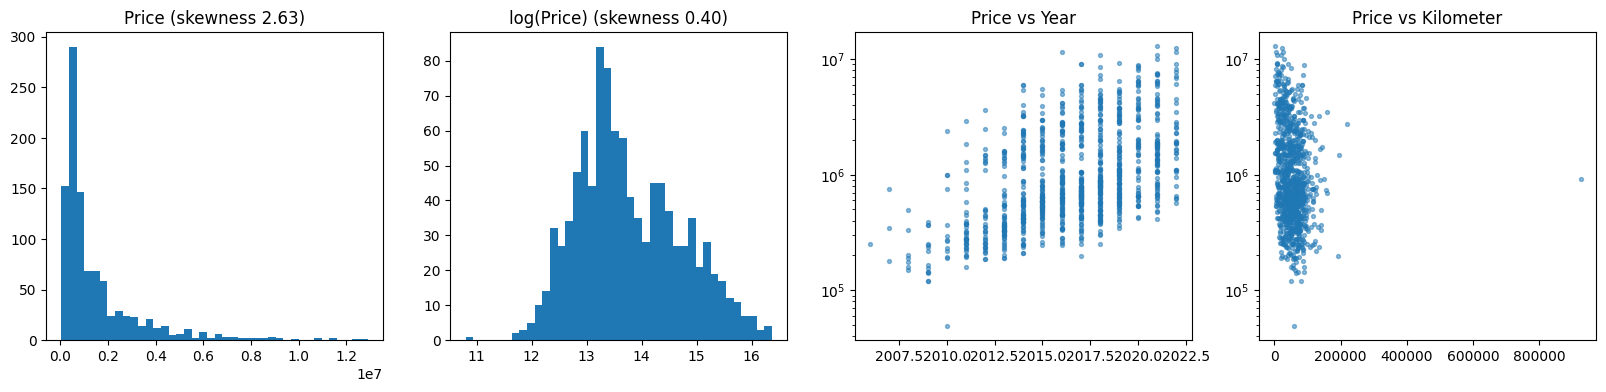

,count,mean
Owner,,
4 or More,1,1.200000e+05
Fourth,2,1.650000e+05
Third,17,9.566471e+05
Second,186,1.398683e+06
First,795,1.574850e+06
UnRegistered Car,8,3.477000e+06


In [20]:
# Exploration of the training set
# Missing values
missing = Xtrain.isna().sum()
display(missing[missing > 0])

# Price, log(Price), Price vs Year and Price vs Kilometer
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
axes[0].hist(ytrain, bins=40)
axes[0].set_title(f"Price (skewness {ytrain.skew():.2f})")
axes[1].hist(np.log(ytrain), bins=40)
axes[1].set_title(f"log(Price) (skewness {np.log(ytrain).skew():.2f})")
axes[2].scatter(Xtrain["Year"], ytrain, s=8, alpha=0.5)
axes[2].set_yscale("log")
axes[2].set_title("Price vs Year")
axes[3].scatter(Xtrain["Kilometer"], ytrain, s=8, alpha=0.5)
axes[3].set_yscale("log")
axes[3].set_title("Price vs Kilometer")
plt.show()

# Mean price for each Owner
display(pd.concat([Xtrain["Owner"], ytrain], axis=1).groupby("Owner")["Price"].agg(["count", "mean"]).sort_values("mean"))

## Data Processing
1. First things first, I had to deal with the missing values. Removing the data wasn't an option, as in that case, lots of the training data would be left out. So, after exploring the features that contain missing values, I decided to act as follows: if the value is numerical, it would be imputed using the median, and for the text features, a new category, "Unknown", would be added.
2. One-Hot Encoder was used with nominal features, and `transmission` (having only Manual and Automatic, based on my observations) is now binary.
3. After inspecting the `Owner` feature, I found it to be ordinal based on its mean, so I used `OrdinalEncoder` for it.
4. And finally, for `Make` and `Location`, I used `TargetEncoder`. I didn't want to encode them using the One-Hot Encoder because of the number of features they would add, which would almost always be zeros. So, I used `TargetEncoder` instead to link the location and car brand to the average price. And after I applied the log() function to both to match the features with the target which is also logged throughout the models.
5. `Color` was removed and `Volume` was added in the Data Preparation section, the effect of both is checked in the ablation below.

In [21]:
# 2. Basic data preprocessing
# 2.1 Handle missing values using some simple approach ->  You need imputation that is fit on train, for example SimpleImputer (median for numeric columns, most-frequent or an "Unknown" category for Drivetrain)
# 2.2 Inspect the individual features and transform them into a suitable form for use with the selected regression models.

owner_order = [['4 or More', 'Fourth', 'Third', 'Second', 'First', 'UnRegistered Car']]
nominal_cols = ['Drivetrain', 'Fuel Type', 'Seller Type']

# It is a function so I can rebuild the preprocessing in the ablation below
def build_preprocessor(nominal_cols):
    const = SimpleImputer(strategy="constant", fill_value="Unknown")
    trgt = TargetEncoder(smooth="auto", target_type="continuous", cv=KFold(5, shuffle=True, random_state=seed))
    return ColumnTransformer([
        ("Numeric imputer", SimpleImputer(strategy="median"), ['Engine', 'Fuel Tank Capacity']),
        ("Nominal One-hot", Pipeline([("Constant imputaion", const), ("One-hot encoding", OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.int8))]), nominal_cols),
        ("Binary Encoding of Transmission", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False, dtype=np.int8), ['Transmission']),
        ("Ordinal Encoding", OrdinalEncoder(categories=owner_order, handle_unknown="use_encoded_value", unknown_value=-1), ['Owner']),
        ("Target Encoding", Pipeline([("Target Encoder", trgt), ("Log", FunctionTransformer(np.log, feature_names_out="one-to-one"))]), ['Location', 'Make']),
    ], remainder="passthrough")

pre = build_preprocessor(nominal_cols)
pre.set_output(transform="pandas")
Xtrain_original = Xtrain
Xval_original = Xval
Xtest_original = Xtest

# Fit on the train set only, the validation set is just transformed
Xtrain = pre.fit_transform(Xtrain, ytrain)
Xval = pre.transform(Xval)

print("train:", Xtrain.shape)
print("validation:", Xval.shape)
print("NaN left:", Xtrain.isna().sum().sum() + Xval.isna().sum().sum())

train: (1009, 27)
validation: (337, 27)
NaN left: 0


In [22]:
# Ablation of Color and Volume using Ridge (RobustScaler, alpha chosen on the validation set)
# The seed is the same, so the train and validation sets are the same as above
def ridge_ablation(drop_color=True, add_volume=True):
    d = raw_data_preprocessing(pd.read_csv('data.csv', na_values=na_values), drop_color, add_volume)
    X = d.drop(columns='Price')
    y = d.Price
    X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.4, random_state=seed)
    X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.5, random_state=seed)

    cols = nominal_cols if drop_color else nominal_cols + ['Color']
    p = build_preprocessor(cols)
    X_tr = p.fit_transform(X_tr, y_tr)
    X_va = p.transform(X_va)

    sc = RobustScaler()
    X_tr = sc.fit_transform(X_tr)
    X_va = sc.transform(X_va)

    rmse = []
    for alpha in np.logspace(-3, 3, 60):
        m = Ridge(alpha)
        m.fit(X_tr, np.log(y_tr))
        rmse.append(root_mean_squared_error(y_va, np.exp(m.predict(X_va))))
    return np.min(rmse)

print("Baseline (without Color, with Volume):", ridge_ablation())
print("With Color:", ridge_ablation(drop_color=False))
print("Without Volume:", ridge_ablation(add_volume=False))

Baseline (without Color, with Volume): 586448.5050158397
With Color: 595866.0199356539
Without Volume: 582261.0203396338


## Ablation of `Color` and `Volume`
The validation RMSE of Ridge Regression is used for the comparison.
1. Keeping `Color` (One-Hot encoded) made the result worse, 595866 instead of 586449, so I left it out.
2. Removing `Volume` made the result slightly better, 582261. The difference is small for a validation set of 337 rows, so I kept `Volume` as a summary of the three correlated size features, but it doesn't affect the result much.

# 3. Linear Regression

## Suitability of the model for this type of problem

Predicting the car price is one of the typical examples of a problem that the Linear Regression model can solve. It is a good choice of model as long as there is an actual linear dependence between input features and the target and as long as the training data represents the actual data well (e.g., the training data includes all sorts of cars and not only luxury cars).

## Obtained results

The linear regression model has practically no hyperparameters to tune. In the experiment I compared no scaling with `StandardScaler`, `MinMaxScaler` and `RobustScaler`. Scaling improved the result a lot (RMSE 1377771 without it, 659144 with it), most likely because features like `Volume` are many orders of magnitude bigger than the others. The three scalers gave practically the same result, so I used `StandardScaler`. From the target exploration, I found that the data is right-skewed, which led me to apply the `log()` function to the training targets. It made the data bell-shaped and lowered the validation RMSE from 903467 (raw target) to 659144.

These are the obtained measure values:

RMSE: 659144.6360117692
<br>
MSE: 434471651183.0877
<br>
R2 score: 0.8535915561999057

In [23]:
# 3.2 Experiment with feature scaling and with the log of the target
scalers = {"no scaling": None, "StandardScaler": StandardScaler, "MinMaxScaler": MinMaxScaler, "RobustScaler": RobustScaler}

for name, scaler_cls in scalers.items():
    if scaler_cls is None:
        Xtrain_s = Xtrain
        Xval_s = Xval
    else:
        sc = scaler_cls()
        Xtrain_s = sc.fit_transform(Xtrain)
        Xval_s = sc.transform(Xval)

    clf_raw = LinearRegression()
    clf_raw.fit(Xtrain_s, ytrain)
    clf_log = LinearRegression()
    clf_log.fit(Xtrain_s, np.log(ytrain))

    print(name)
    print("RMSE, raw target:", root_mean_squared_error(yval, clf_raw.predict(Xval_s)))
    print("RMSE, log target:", root_mean_squared_error(yval, np.exp(clf_log.predict(Xval_s))))

no scaling
RMSE, raw target: 1290776.8507479588
RMSE, log target: 1377771.8446368147
StandardScaler
RMSE, raw target: 903467.094099534
RMSE, log target: 659144.6360117692
MinMaxScaler
RMSE, raw target: 905583.8247584909
RMSE, log target: 659163.8100534817
RobustScaler
RMSE, raw target: 905583.8247584908
RMSE, log target: 659163.8100534825


RMSE: 659144.6360117692
MSE: 434471651183.0877
R2 score: 0.8535915561999057


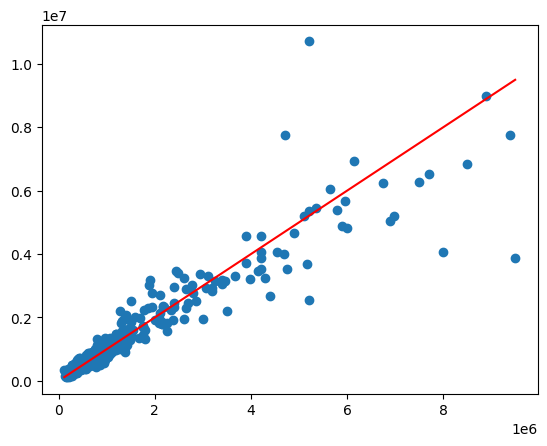

In [24]:
# 3.2 Experiment with feature scaling
# 3.3 Choose hyperparameters to tune and find suitable values with respect to MSE.
scaler = StandardScaler()

Xtrain_scaled = scaler.fit_transform(Xtrain)
Xval_scaled = scaler.transform(Xval)
ytrain_log = np.log(ytrain)
    
clf = LinearRegression()
clf.fit(Xtrain_scaled, ytrain_log)
Y_predict_val = np.exp(clf.predict(Xval_scaled))

output(y=yval, y_pred=Y_predict_val)

# 4. Ridge Regression

## Suitability of the model for this type of problem
The ridge regression fits this problem as well as the linear does, however, additionally to what linear regression does, ridge regression reduces chance of overfitting, handles collinearity, and it is considered to perform better on small/noisy samples than linear regression. Which is a useful case in this problem, as our dataset consists of multiple features that may be considered collinear, in addition to that the dataset consists multiple clear outliers (e.g luxury cars in exotic locations).


## Obtained results
Initially the appropriate scaler was chosen - `RobustScaler` performed slightly better than `StandardScaler` and `MinMaxScaler` (586449 vs 658758 and 613136). The model without scaling got 583467, which is only slightly better, but I kept `RobustScaler` because Ridge penalizes the coefficients and that depends on the scale of the features. The alpha was chosen through the iterative search over 60 values from 1e-3 to 1e3 (log scale), the best one was 4.58 and it is inside of the range, not on its edge.
<br>
These are the obtained measure values:
<br>
RMSE: 586448.5050158406
<br>
MSE: 343921849035.3145
<br>
R2 score: 0.8841050674560758

c:\Users\72263\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: Ill-conditioned matrix (rcond=1.54087e-25): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
c:\Users\72263\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: Ill-conditioned matrix (rcond=1.94741e-25): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
c:\Users\72263\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: Ill-conditioned matrix (rcond=2.46121e-25): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
c:\Users\72263\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: Ill-conditioned matrix (rcond=3.11057e-25): result may not be accurate.
  return linalg.solve

no scaling: best RMSE 583466.5371756853, alpha 29.82471286216894
StandardScaler: best RMSE 658757.6892909316, alpha 3.6251170499885355
MinMaxScaler: best RMSE 613135.6700676086, alpha 0.8895134973108236
RobustScaler: best RMSE 586448.5050158406, alpha 4.581597669054491


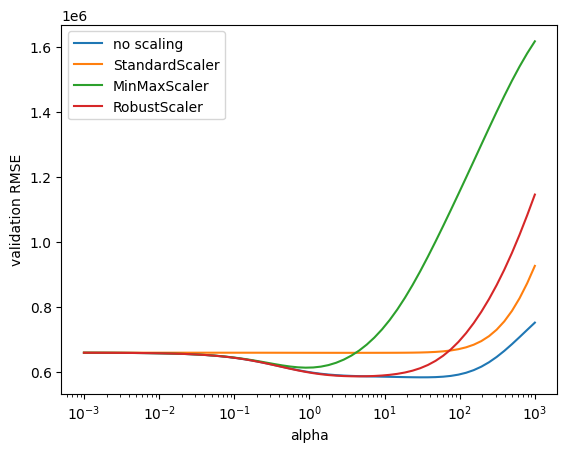

In [25]:
# 4.2 Experiment with feature scaling, alpha is tuned for each of the scalers
alphas = np.logspace(-3, 3, 60)
ytrain_log = np.log(ytrain)

for name, scaler_cls in scalers.items():
    if scaler_cls is None:
        Xtrain_s = Xtrain
        Xval_s = Xval
    else:
        sc = scaler_cls()
        Xtrain_s = sc.fit_transform(Xtrain)
        Xval_s = sc.transform(Xval)

    rmse_s = []
    for alpha in alphas:
        clf_s = Ridge(alpha)
        clf_s.fit(Xtrain_s, ytrain_log)
        rmse_s.append(root_mean_squared_error(y_true=yval, y_pred=np.exp(clf_s.predict(Xval_s))))

    plt.plot(alphas, rmse_s, label=name)
    print(f"{name}: best RMSE {np.min(rmse_s)}, alpha {alphas[np.argmin(rmse_s)]}")

plt.xscale("log")
plt.xlabel("alpha")
plt.ylabel("validation RMSE")
plt.legend()
plt.show()

Optimal alpha: 4.581597669054491, RMSE: 586448.5050158406
RMSE: 586448.5050158406
MSE: 343921849035.3145
R2 score: 0.8841050674560758


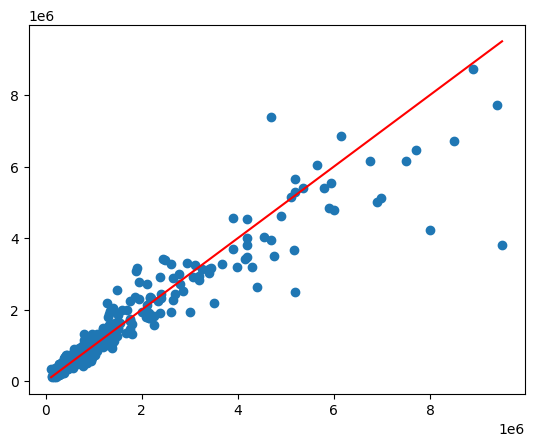

In [26]:
# 4.2 Experiment with feature scaling
# 4.3 Choose hyperparameters to tune and find suitable values with respect to MSE.
# 4.4 For the model with the best hyperparameter values on the validation set report its MSE.
robust_scaler = RobustScaler()

Xtrain_scaled = robust_scaler.fit_transform(Xtrain)
Xval_scaled = robust_scaler.transform(Xval)
ytrain_log = np.log(ytrain)

alphas = np.logspace(-3, 3, 60)
val_rmse = []

for alpha in alphas:
    clf_ridge = Ridge(alpha)
    clf_ridge.fit(Xtrain_scaled, ytrain_log)

    Y_predict_ridge = np.exp(clf_ridge.predict(Xval_scaled))
    val_rmse.append(root_mean_squared_error(y_true=yval, y_pred=Y_predict_ridge))

optimal_alpha = alphas[np.argmin(val_rmse)]
minValue = np.min(val_rmse)
print(f"Optimal alpha: {optimal_alpha}, RMSE: {minValue}")

clf_ridge = Ridge(optimal_alpha)
clf_ridge.fit(Xtrain_scaled, ytrain_log)

Y_predict_ridge = np.exp(clf_ridge.predict(Xval_scaled))

output(y=yval, y_pred=Y_predict_ridge)

# 5. Decision tree

## Suitability of the model for this type of problem
Decision Tree is a suitable model for predicting car prices because it can capture both linear and non-linear relationships between input features and the target. Unlike Linear Regression, it does not assume a linear relationship between the features and the target. It can also handle complex interactions between features and is relatively easy to interpret. However, decision trees can easily overfit the training data, so controlling their depth and other hyperparameters is important to achieve good generalization.

## Obtained results
I went through all the combinations (144 in total) of these hyperparameters: `splitter` (best, random), `max_depth` (3, 5, 8, 12, 16, None), `min_samples_split` (2, 10, 30) and `min_samples_leaf` (1, 5, 10, 20). The best combination on the validation set was `max_depth=12`, `min_samples_split=10`, `min_samples_leaf=1` and `splitter='random'`.
<br>
Despite my high expectations, a single decision tree underperforms compared to the Ridge Regression model. The current data processing is the best among the pipelines I've experimented with. Scaling was left out on purpose because it doesn't affect the model's outcome quality.
<br>
These are the obtained measure values:
<br>
RMSE: 660351.1790737081
<br>
MSE: 436063679704.0366
<br>
R2 score: 0.8530550737444847

{'max_depth': 12,
 'min_samples_leaf': 1,
 'min_samples_split': 10,
 'splitter': 'random'}

RMSE: 660351.1790737081
MSE: 436063679704.0366
R2 score: 0.8530550737444847


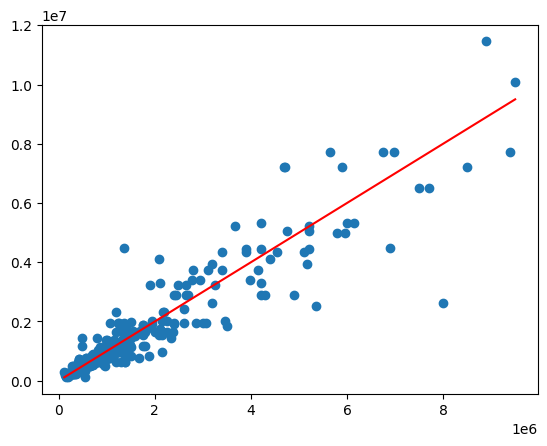

In [27]:
# 5.2 Experiment with feature scaling (not needed for the tree)
# 5.3 Choose hyperparameters to tune and find suitable values with respect to MSE.
# 5.4 For the model with the best hyperparameter values on the validation set report its MSE.
ytrain_log = np.log(ytrain)

param_grid = {
    'splitter': ['best', 'random'],
    'max_depth': [3, 5, 8, 12, 16, None],
    'min_samples_split': [2, 10, 30],
    'min_samples_leaf': [1, 5, 10, 20],
}
param_comb = list(ParameterGrid(param_grid))

val_mse = []

for params in param_comb:
    clf_tree = DecisionTreeRegressor(**params, random_state=seed)
    clf_tree.fit(Xtrain, ytrain_log)

    pred_val = np.exp(clf_tree.predict(Xval))

    val_mse.append(mean_squared_error(yval, pred_val))

best_idx = np.argmin(val_mse)
best_params = param_comb[best_idx]
display(best_params)

clf_tree = DecisionTreeRegressor(**best_params, random_state=seed)
clf_tree.fit(Xtrain, ytrain_log)
pred_val = np.exp(clf_tree.predict(Xval))

output(yval, pred_val)

## Comparison of the models on the validation set
Ridge Regression has the lowest validation RMSE (586449 vs 659144 for Linear Regression and 660351 for the Decision Tree), so it is my final model.

In [28]:
# Validation results of all 3 models
val_preds = {
    "Linear regression": Y_predict_val,
    "Ridge regression": Y_predict_ridge,
    "Decision tree": pred_val,
}

val_results = pd.DataFrame({
    name: {
        "RMSE": root_mean_squared_error(yval, p),
        "MSE": mean_squared_error(yval, p),
        "R2": r2_score(yval, p),
    }
    for name, p in val_preds.items()
}).T
display(val_results.style.format({"RMSE": "{:,.0f}", "MSE": "{:,.0f}", "R2": "{:.3f}"}))

,RMSE,MSE,R2
Linear regression,"659,145","434,471,651,183",0.854
Ridge regression,"586,449","343,921,849,035",0.884
Decision tree,"660,351","436,063,679,704",0.853


# 6. Estimate the prediction error to expect on new data
I've decided that the final model will be the `RidgeRegression` model based on the validation set. Now I wanna run all 3 models on the test data to see how optimistic was the validation error. Attention: I will not change my mind about the model based on the test data - I already have my final model and it is RidgeRegression as it outperforms all other models in validation.
<br>
So here I compare all 3 models, however, before doing it I retrain them on the training set and validation set combined. I keep the hyperparameters and everything else from before, however, retraining the models gives them more data and context.

In [29]:
# Combine train set + validation. Re-process the data.
ytrainval = pd.concat([ytrain, yval])
ytrainval_log = np.log(ytrainval)

Xtrainval = pre.fit_transform(pd.concat([Xtrain_original, Xval_original]), ytrainval)
Xtest = pre.transform(Xtest_original)

# Linear regression
Xtrainval_scaled = scaler.fit_transform(Xtrainval)
Xtest_scaled = scaler.transform(Xtest)

clf.fit(Xtrainval_scaled, ytrainval_log)
lin_pred = np.exp(clf.predict(Xtest_scaled))

# Ridge regression
Xtrainval_ridge_scaled = robust_scaler.fit_transform(Xtrainval)
Xtest_ridge_scaled = robust_scaler.transform(Xtest)

clf_ridge.fit(Xtrainval_ridge_scaled, ytrainval_log)
ridge_pred = np.exp(clf_ridge.predict(Xtest_ridge_scaled))

# Decision tree
clf_tree.fit(Xtrainval, ytrainval_log)
tree_pred = np.exp(clf_tree.predict(Xtest))

,RMSE,MSE,R2
Linear regression,"537,006","288,374,917,268",0.912
Ridge regression,"542,837","294,672,140,239",0.911
Decision tree,"581,636","338,300,885,964",0.897


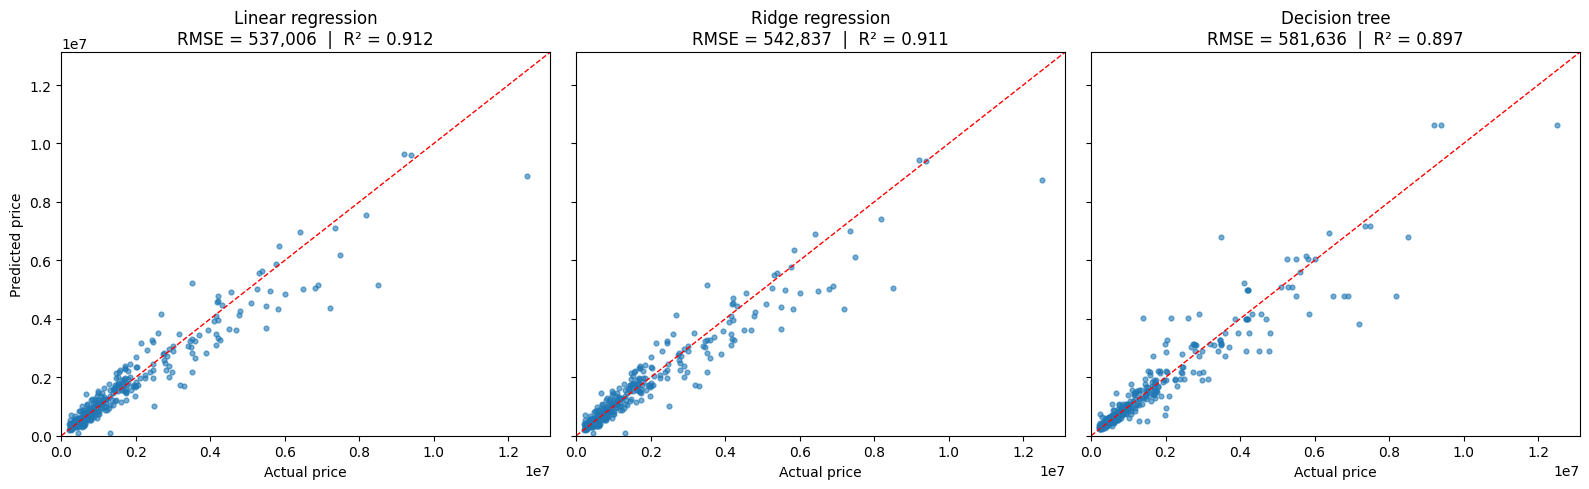

In [30]:
test_preds = {
      "Linear regression": lin_pred,
      "Ridge regression": ridge_pred,
      "Decision tree": tree_pred,
  }

  # --- Metrics table (test set, raw price) ---
test_results = pd.DataFrame({
      name: {
          "RMSE": root_mean_squared_error(ytest, p),
          "MSE": mean_squared_error(ytest, p),
          "R2": r2_score(ytest, p),
      }
      for name, p in test_preds.items()
  }).T
display(test_results.style.format({"RMSE": "{:,.0f}", "MSE": "{:,.0f}", "R2": "{:.3f}"}))

  # --- Actual vs predicted, one panel per model, shared axes ---
lim = (0, max(ytest.max(), *(p.max() for p in test_preds.values())) * 1.05)
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
for ax, (name, p) in zip(axes, test_preds.items()):
    ax.scatter(ytest, p, s=12, alpha=0.6)
    ax.plot(lim, lim, "r--", linewidth=1)
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_title(f"{name}\nRMSE = {test_results.loc[name, 'RMSE']:,.0f}  |  R² = {test_results.loc[name, 'R2']:.3f}")
    ax.set_xlabel("Actual price")
axes[0].set_ylabel("Predicted price")
plt.tight_layout()
plt.show()

## Test error of the final model
The final model is Ridge Regression and its RMSE on the test set is about 543000 (MSE 2.95e11, R2 0.911). The test set wasn't used for fitting, tuning or choosing the model, so this is the error I expect on new data. In other words, the predicted price will typically be off by a few hundred thousand, and as RMSE punishes the large errors, it is influenced the most by the expensive cars. The graph shows it as well: the cheaper cars are very close to the red line, but the expensive ones are spread out and mostly underpredicted (e.g. the most expensive car, which is predicted at about 9M instead of 12.5M).
<br>
Comparison of all 3 models on the test set (only for reporting, the model was chosen before):
1. The test RMSE is 537006 for Linear Regression, 542837 for Ridge Regression and 581636 for the Decision Tree.
2. Linear and Ridge Regression are practically the same here, they differ by about 1% and the graphs look almost identical. The advantage of Ridge from the validation set didn't hold up, so I think regularization doesn't matter much for this data. I still keep Ridge, as I chose the final model on the validation set before seeing the test results, and changing it now would make the test estimate optimistic.
3. The Decision Tree is the worst one on the test set as well, its predictions are more spread out around the red line.
4. The test error of Ridge is lower than the validation one (586449), but both sets have only 337 rows and the final models were retrained on more data, so I wouldn't read much into it.

# 7. Final evaluation
The final model is the Ridge Regression retrained on the train + validation sets. I didn't add the test set to the final fit, so the test RMSE above describes exactly the model that makes the predictions. The evaluation data goes through the same fitted `pre` and `robust_scaler`, and `exp()` is applied to the predictions of the model. The result is saved to `results.csv`.

In [ ]:
# 7.1 Load the evaluation data from `evaluation.csv`
# Run the notebook from the top, `pre`, `robust_scaler` and `clf_ridge` come from the retraining in section 6
evaluation = pd.read_csv('evaluation.csv', na_values=na_values)
evaluation_raw = raw_data_preprocessing(evaluation)
evaluation_raw_pre = pre.transform(evaluation_raw)
evaluation_raw_pre_scaled = robust_scaler.transform(evaluation_raw_pre)

# 7.2 Use your final model to compute predictions for these data.
evaluation_results = np.exp(clf_ridge.predict(evaluation_raw_pre_scaled))

# 7.3 Create a file `results.csv` containing the predictions in a column named **Price** and the corresponding identifiers in a column named **ID** (keep these column names exactly).
submission = pd.DataFrame({
    "ID": evaluation["ID"].values,
    "Price": evaluation_results,
})

submission.to_csv("results.csv", index=False)